In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data from previous step
X_train = pd.read_pickle('../data/processed/X_train.pkl')
X_test = pd.read_pickle('../data/processed/X_test.pkl')
y_train = pd.read_pickle('../data/processed/y_train.pkl')
y_test = pd.read_pickle('../data/processed/y_test.pkl')

print("Data loaded successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

Data loaded successfully!
X_train shape: (5616, 19)
X_test shape : (1405, 19)


In [13]:
# Make copies so we don't change original data
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Identify column types
binary_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'PaperlessBilling'
]

multi_class_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("Binary columns:", binary_cols)
print("Multi-class columns:", multi_class_cols)
print("Numeric columns:", numeric_cols)


# Encode Binary columns (Yes/No → 1/0)
def encode_binary(df):
    df = df.copy()
    
    # gender
    df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
    
    # Other Yes/No columns
    yes_no_cols = ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
    for col in yes_no_cols:
        df[col] = df[col].map({'Yes': 1, 'No': 0})
    
    return df

X_train_fe = encode_binary(X_train_fe)
X_test_fe = encode_binary(X_test_fe)


# Create new useful features

def create_new_features(df):
    df = df.copy()
    
    # Average monthly charge (avoid division by zero)
    df['AvgMonthlyCharges'] = df['TotalCharges'] / df['tenure'].replace(0, 1)
    
    # Has internet service (1 if has any internet, 0 otherwise)
    df['HasInternet'] = (df['InternetService'] != 'No').astype(int)
    
    # Number of additional services
    service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
                    'TechSupport', 'StreamingTV', 'StreamingMovies']
    
    df['NumAdditionalServices'] = 0
    for col in service_cols:
        df['NumAdditionalServices'] += (df[col] == 'Yes').astype(int)
    
    return df

X_train_fe = create_new_features(X_train_fe)
X_test_fe = create_new_features(X_test_fe)


# One-Hot Encoding for multi-class columns

X_train_fe = pd.get_dummies(X_train_fe, columns=multi_class_cols, drop_first=True)
X_test_fe = pd.get_dummies(X_test_fe, columns=multi_class_cols, drop_first=True)

# Make sure train and test have the same columns
X_train_fe, X_test_fe = X_train_fe.align(X_test_fe, join='left', axis=1, fill_value=0)

print("\nShape after encoding:")
print("X_train_fe:", X_train_fe.shape)
print("X_test_fe :", X_test_fe.shape)


#۹۸ Check final columns

print("\nFinal columns:")
print(X_train_fe.columns.tolist())

X_train_fe.head().T

Binary columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
Multi-class columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']

Shape after encoding:
X_train_fe: (5616, 33)
X_test_fe : (1405, 33)

Final columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharges', 'HasInternet', 'NumAdditionalServices', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No intern

,2629,2650,1418,5774,2425
gender,1,0,1,1,1
SeniorCitizen,0,0,0,0,0
Partner,0,0,1,0,0
Dependents,0,0,1,0,0
tenure,2,15,67,5,26
PhoneService,1,1,1,1,1
PaperlessBilling,0,1,1,1,1
MonthlyCharges,70.7,84.35,89.55,65.6,20.3
TotalCharges,140.7,1302.65,6373.1,339.9,511.25
AvgMonthlyCharges,70.35,86.843333,95.120896,67.98,19.663462


Shape before feature selection:
X_train: (5616, 33)
X_test : (1405, 33)

Features removed by low variance: 0
Shape after removing low variance features: (5616, 33)

Highly correlated features (corr > 0.85):
['AvgMonthlyCharges', 'MultipleLines_No phone service', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service']

Top 15 most important features:
                           feature  importance
8                     TotalCharges    0.157824
4                           tenure    0.147619
9                AvgMonthlyCharges    0.131028
7                   MonthlyCharges    0.127741
14     InternetService_Fiber optic    0.037185
11           NumAdditionalServices    0.035061
31  PaymentMethod_Electronic check    0.033265
29               Contract_Two year    0.025851
6                 PaperlessBilling  

/var/folders/1t/0m9fmtx547q3gfyb1pygwvgm0000gn/T/ipykernel_96988/3290223695.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(15), x='importance', y='feature', palette='viridis')


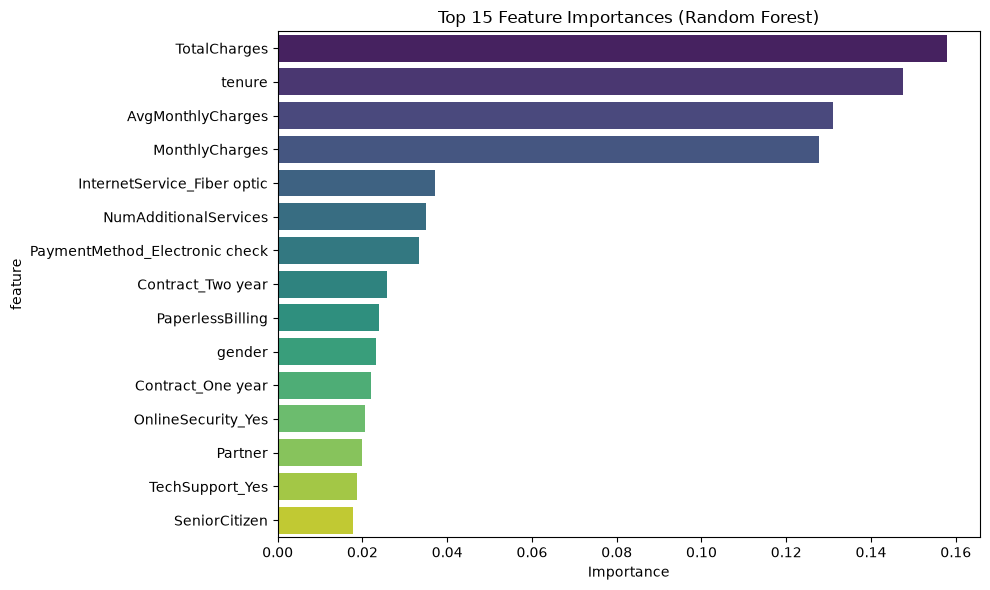


Final shape after Feature Selection:
X_train_fs: (5616, 33)
X_test_fs : (1405, 33)


In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure we work with the encoded data
X_train_fs = X_train_fe.copy()
X_test_fs = X_test_fe.copy()

print("Shape before feature selection:")
print("X_train:", X_train_fs.shape)
print("X_test :", X_test_fs.shape)

# 1. Remove low variance features
selector = VarianceThreshold(threshold=0.01)   # remove features with almost no variance
selector.fit(X_train_fs)

# Get remaining columns
remaining_cols = X_train_fs.columns[selector.get_support()]
X_train_fs = X_train_fs[remaining_cols]
X_test_fs = X_test_fs[remaining_cols]

print(f"\nFeatures removed by low variance: {X_train_fe.shape[1] - X_train_fs.shape[1]}")
print("Shape after removing low variance features:", X_train_fs.shape)

# 2. Check correlation (optional but useful)

# Calculate correlation matrix
corr_matrix = X_train_fs.corr().abs()

# Find highly correlated pairs (above 0.85)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_features = [column for column in upper.columns if any(upper[column] > 0.85)]

print("\nHighly correlated features (corr > 0.85):")
print(high_corr_features)

# You can drop them if you want (optional)
# X_train_fs = X_train_fs.drop(columns=high_corr_features)
# X_test_fs = X_test_fs.drop(columns=high_corr_features)

# 3. Feature Importance with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_fs, y_train)

# Create importance dataframe
importance_df = pd.DataFrame({
    'feature': X_train_fs.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 15 most important features:")
print(importance_df.head(15))

# Plot top features
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='importance', y='feature', palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# 4. Optional: Keep only top N features

# Uncomment the lines below if you want to keep only top features
# top_n = 20
# top_features = importance_df['feature'].head(top_n).tolist()
# X_train_fs = X_train_fs[top_features]
# X_test_fs = X_test_fs[top_features]

print("\nFinal shape after Feature Selection:")
print("X_train_fs:", X_train_fs.shape)
print("X_test_fs :", X_test_fs.shape)